# Predictive Customer Churn Classifier (Random Forest & XGBoost)
**Task 3 – Datheon AI Internship**

Predict telecom customer churn on the Telco Customer Churn dataset. Steps: clean `TotalCharges`, One-Hot Encoding, handle class imbalance with **SMOTE**, train **Random Forest** and **XGBoost** with stratified cross-validation, and evaluate with **ROC-AUC (target > 0.80)**, confusion matrices and top-10 feature importances.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score)
from xgboost import XGBClassifier

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
%matplotlib inline

## 2. Load the Dataset

In [2]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()
df.describe(include="all").T.head(25)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Data Cleaning
### 3.1 Convert `TotalCharges` to numeric and handle nulls
`TotalCharges` is stored as text because some rows contain blank spaces.

In [4]:
print("TotalCharges dtype before:", df["TotalCharges"].dtype)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("TotalCharges dtype after :", df["TotalCharges"].dtype)
print("Null TotalCharges:", df["TotalCharges"].isnull().sum())

# Inspect the null rows
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

TotalCharges dtype before: str
TotalCharges dtype after : float64
Null TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


All null rows have `tenure = 0` (brand-new customers who haven't been billed yet), so the logical fill value is **0**.

In [5]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df = df.drop(columns="customerID")          # identifier, no predictive value
print("Remaining nulls:", df.isnull().sum().sum())

Remaining nulls: 0


### 3.2 Target encoding & class imbalance check

Churn
0    5174
1    1869
Name: count, dtype: int64

Churn rate: 26.54%   |   Imbalance ratio (No:Yes) = 2.77 : 1


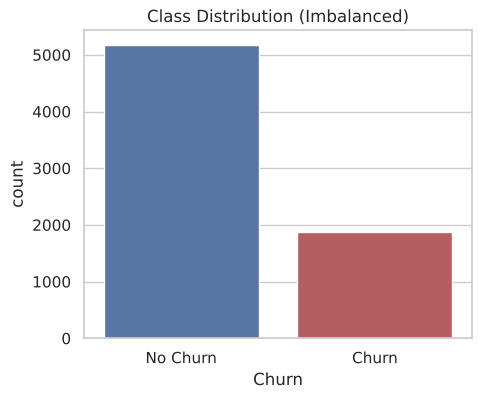

In [6]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

counts = df["Churn"].value_counts()
print(counts)
print(f"\nChurn rate: {counts[1] / len(df):.2%}   |   Imbalance ratio (No:Yes) = {counts[0] / counts[1]:.2f} : 1")

plt.figure(figsize=(5, 4))
sns.countplot(x="Churn", data=df, palette=["#4c72b0", "#c44e52"])
plt.xticks([0, 1], ["No Churn", "Churn"])
plt.title("Class Distribution (Imbalanced)")
plt.show()

## 4. Exploratory Analysis

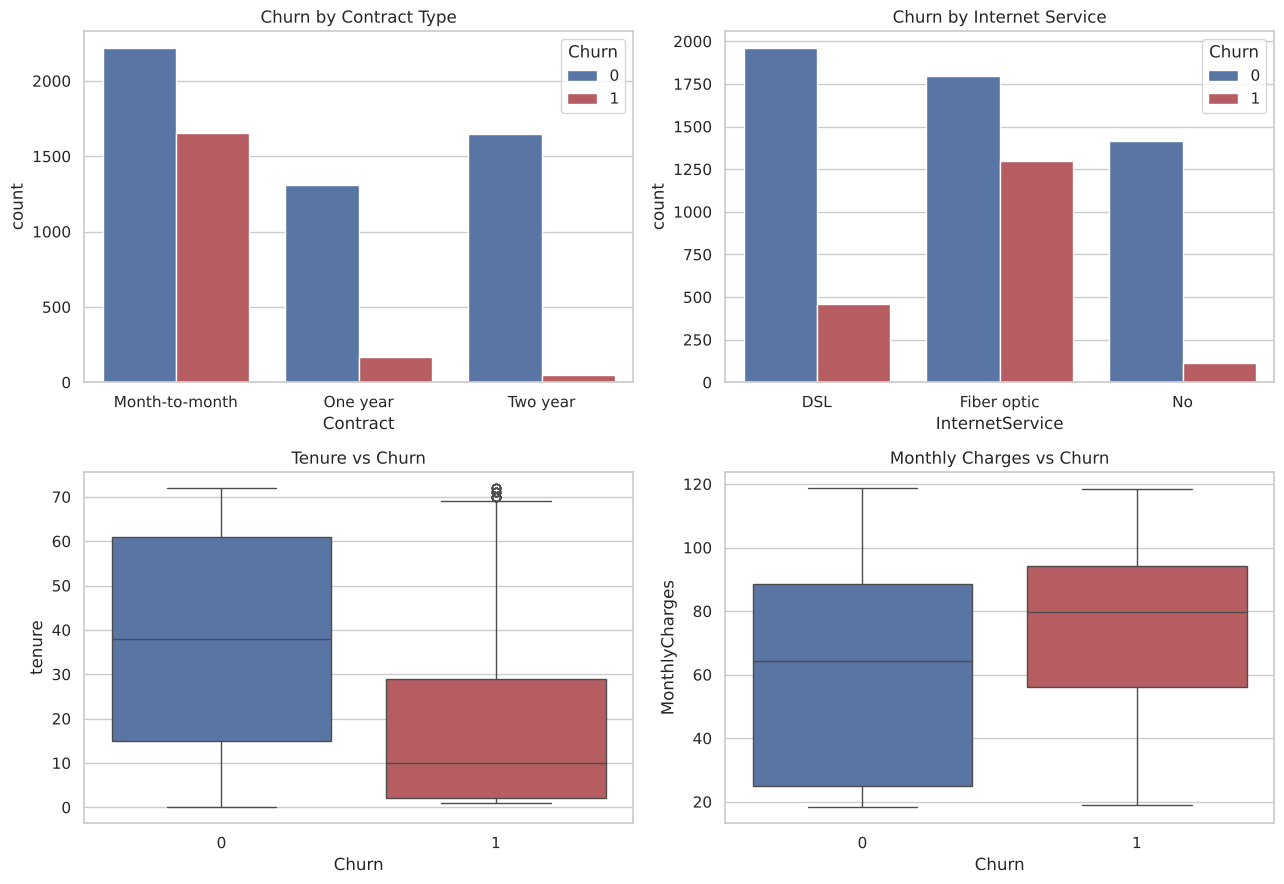

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.countplot(data=df, x="Contract", hue="Churn", ax=ax[0, 0], palette=["#4c72b0", "#c44e52"])
ax[0, 0].set_title("Churn by Contract Type")
sns.countplot(data=df, x="InternetService", hue="Churn", ax=ax[0, 1], palette=["#4c72b0", "#c44e52"])
ax[0, 1].set_title("Churn by Internet Service")
sns.boxplot(data=df, x="Churn", y="tenure", ax=ax[1, 0], palette=["#4c72b0", "#c44e52"])
ax[1, 0].set_title("Tenure vs Churn")
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=ax[1, 1], palette=["#4c72b0", "#c44e52"])
ax[1, 1].set_title("Monthly Charges vs Churn")
plt.tight_layout(); plt.show()

## 5. Train / Test Split
Stratified split keeps the same churn ratio in train and test.

In [8]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train churn rate:", round(y_train.mean(), 4), "| Test churn rate:", round(y_test.mean(), 4))

Train: (5634, 19) | Test: (1409, 19)
Train churn rate: 0.2654 | Test churn rate: 0.2654


## 6. Preprocessing (OneHotEncoder)

In [9]:
cat_features = X.select_dtypes(include="object").columns.tolist()
num_features = X.select_dtypes(exclude="object").columns.tolist()
print("Categorical:", cat_features)
print("Numeric    :", num_features)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
])

Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numeric    : ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


## 7. Handling Class Imbalance with SMOTE
SMOTE is placed **inside** an `imblearn` Pipeline, so synthetic samples are generated only from the *training* portion of each CV fold. This avoids leaking synthetic/validation data into evaluation.

In [10]:
def build_pipeline(model, use_smote=True):
    steps = [("prep", preprocessor)]
    if use_smote:
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", model))
    return ImbPipeline(steps)

rf_model = RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=3,
                                  random_state=RANDOM_STATE, n_jobs=-1)
xgb_model = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                          subsample=0.8, colsample_bytree=0.8,
                          eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1)

pipelines = {
    "Random Forest + SMOTE": build_pipeline(rf_model),
    "XGBoost + SMOTE": build_pipeline(xgb_model),
}

## 8. Cross-Validation (5-fold Stratified, ROC-AUC)

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_rows.append({"Model": name, "CV ROC-AUC (mean)": scores.mean(), "CV ROC-AUC (std)": scores.std()})
    print(f"{name:25s} -> folds: {np.round(scores, 4)}  mean={scores.mean():.4f}")

pd.DataFrame(cv_rows).set_index("Model").round(4)

Random Forest + SMOTE     -> folds: [0.8322 0.829  0.8385 0.8444 0.8523]  mean=0.8393


XGBoost + SMOTE           -> folds: [0.8338 0.8305 0.8422 0.8554 0.8507]  mean=0.8425


,CV ROC-AUC (mean),CV ROC-AUC (std)
Model,,
Random Forest + SMOTE,0.8393,0.0084
XGBoost + SMOTE,0.8425,0.0095


## 9. Train Final Models & Predict on Test Set

In [12]:
probas, preds = {}, {}
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    probas[name] = pipe.predict_proba(X_test)[:, 1]
    preds[name] = pipe.predict(X_test)
print("Models trained.")

Models trained.


## 10. Evaluation Metrics

In [13]:
rows = []
for name in pipelines:
    rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, probas[name]),
        "Accuracy": accuracy_score(y_test, preds[name]),
        "Precision": precision_score(y_test, preds[name]),
        "Recall": recall_score(y_test, preds[name]),
        "F1-score": f1_score(y_test, preds[name]),
    })
results = pd.DataFrame(rows).set_index("Model").round(4)
display(results)

for name in pipelines:
    status = "PASSED" if results.loc[name, "ROC-AUC"] > 0.80 else "NOT MET"
    print(f"{name:25s} ROC-AUC = {results.loc[name, 'ROC-AUC']:.4f}  -> target (>0.80): {status}")

,ROC-AUC,Accuracy,Precision,Recall,F1-score
Model,,,,,
Random Forest + SMOTE,0.8346,0.7679,0.5530,0.6551,0.5998
XGBoost + SMOTE,0.8388,0.7800,0.5784,0.6310,0.6036


Random Forest + SMOTE     ROC-AUC = 0.8346  -> target (>0.80): PASSED
XGBoost + SMOTE           ROC-AUC = 0.8388  -> target (>0.80): PASSED


In [14]:
for name in pipelines:
    print("="*60); print(name); print("="*60)
    print(classification_report(y_test, preds[name], target_names=["No Churn", "Churn"]))

Random Forest + SMOTE
              precision    recall  f1-score   support

    No Churn       0.87      0.81      0.84      1035
       Churn       0.55      0.66      0.60       374

    accuracy                           0.77      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.77      0.77      1409

XGBoost + SMOTE
              precision    recall  f1-score   support

    No Churn       0.86      0.83      0.85      1035
       Churn       0.58      0.63      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.73      1409
weighted avg       0.79      0.78      0.78      1409



## 11. ROC Curves

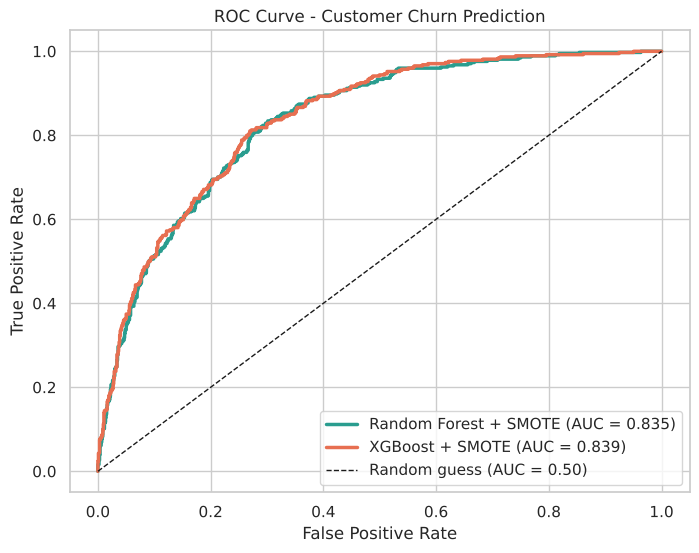

In [15]:
plt.figure(figsize=(8, 6))
for name, color in zip(pipelines, ["#2a9d8f", "#e76f51"]):
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    auc = roc_auc_score(y_test, probas[name])
    plt.plot(fpr, tpr, lw=2.5, color=color, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess (AUC = 0.50)")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend(loc="lower right")
plt.show()

## 12. Confusion Matrices

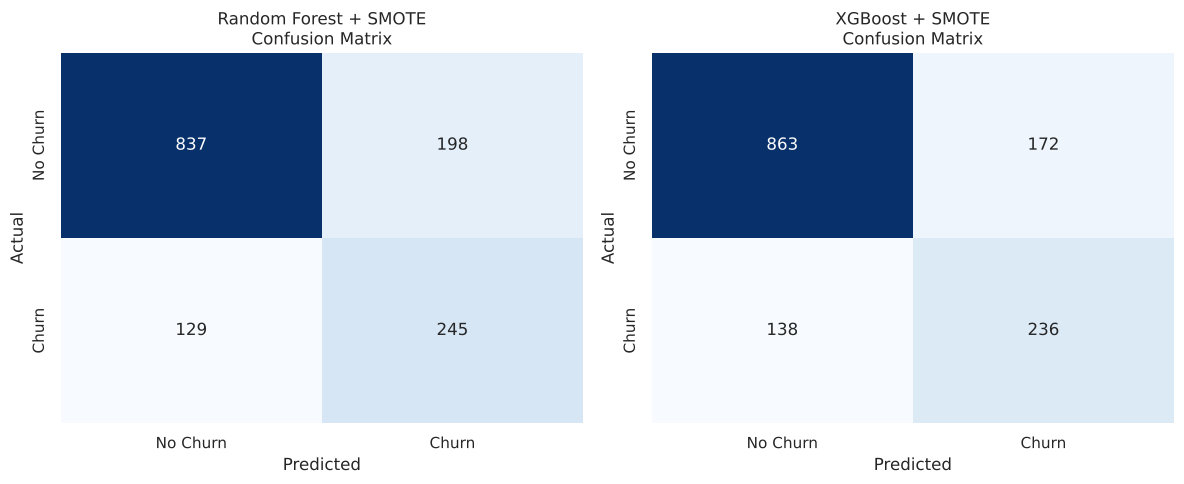

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, pipelines):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"])
    ax.set_title(f"{name}\nConfusion Matrix")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

## 13. Top 10 Most Influential Features

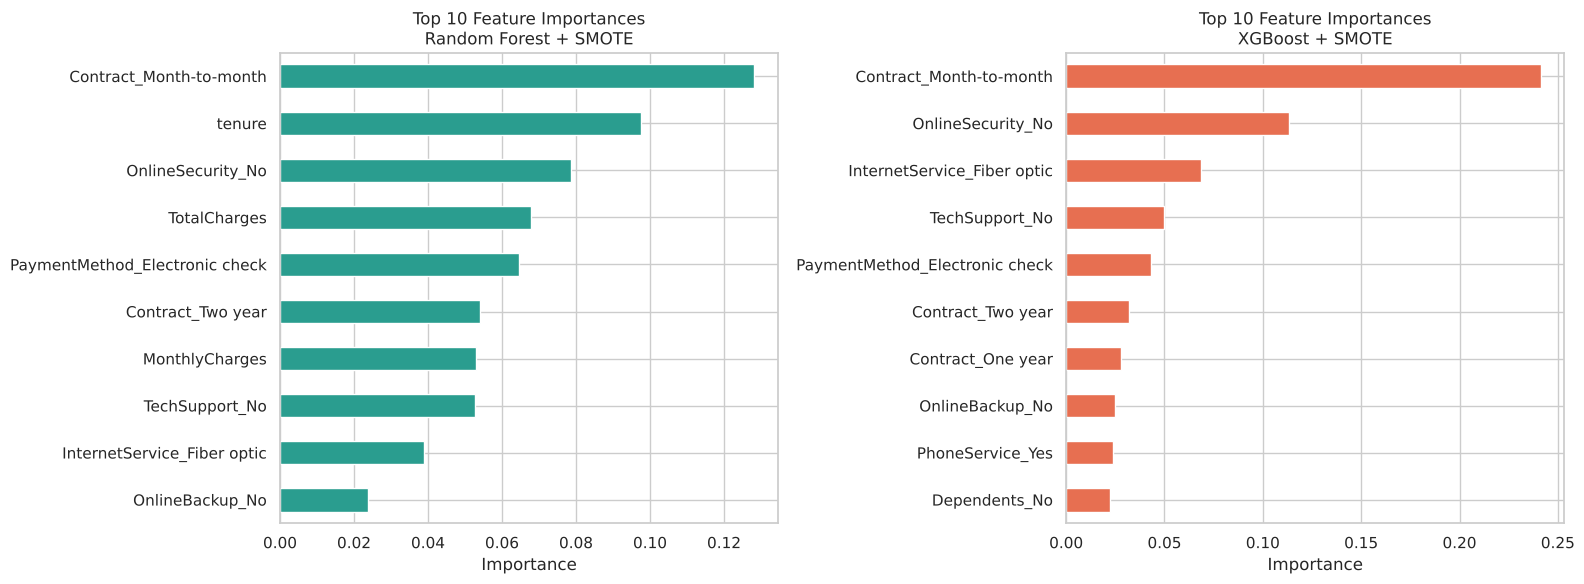

,Random Forest + SMOTE,XGBoost + SMOTE
Contract_Month-to-month,0.1282,0.2412
Contract_One year,NaN,0.0277
Contract_Two year,0.0540,0.0321
Dependents_No,NaN,0.0222
InternetService_Fiber optic,0.0390,0.0685
MonthlyCharges,0.0531,NaN
OnlineBackup_No,0.0237,0.0248
OnlineSecurity_No,0.0787,0.1134
PaymentMethod_Electronic check,0.0647,0.0433
PhoneService_Yes,NaN,0.0238


In [17]:
feat_names = pipelines["Random Forest + SMOTE"].named_steps["prep"].get_feature_names_out()
feat_names = [f.replace("num__", "").replace("cat__", "") for f in feat_names]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top_tables = {}
for ax, name, color in zip(axes, pipelines, ["#2a9d8f", "#e76f51"]):
    importances = pipelines[name].named_steps["model"].feature_importances_
    top = (pd.Series(importances, index=feat_names).sort_values(ascending=False).head(10))
    top_tables[name] = top
    top[::-1].plot(kind="barh", ax=ax, color=color)
    ax.set_title(f"Top 10 Feature Importances\n{name}")
    ax.set_xlabel("Importance")
plt.tight_layout(); plt.show()

pd.DataFrame(top_tables).round(4)

## 14. Effect of SMOTE (Baseline vs Balanced)
Quick check of what class balancing changes. ROC-AUC is threshold-independent, while **recall on the churn class** shows the practical benefit of balancing.

In [18]:
baseline_pipes = {
    "Random Forest (no SMOTE)": build_pipeline(rf_model, use_smote=False),
    "XGBoost (no SMOTE)": build_pipeline(xgb_model, use_smote=False),
}
cmp_rows = []
for name, pipe in baseline_pipes.items():
    pipe.fit(X_train, y_train)
    p, pr = pipe.predict(X_test), pipe.predict_proba(X_test)[:, 1]
    cmp_rows.append({"Model": name, "ROC-AUC": roc_auc_score(y_test, pr),
                     "Churn Recall": recall_score(y_test, p), "Churn Precision": precision_score(y_test, p),
                     "F1": f1_score(y_test, p)})
for name in pipelines:
    cmp_rows.append({"Model": name, "ROC-AUC": results.loc[name, "ROC-AUC"],
                     "Churn Recall": results.loc[name, "Recall"], "Churn Precision": results.loc[name, "Precision"],
                     "F1": results.loc[name, "F1-score"]})
pd.DataFrame(cmp_rows).set_index("Model").round(4)

,ROC-AUC,Churn Recall,Churn Precision,F1
Model,,,,
Random Forest (no SMOTE),0.8393,0.5134,0.6553,0.5757
XGBoost (no SMOTE),0.8413,0.5267,0.6678,0.5889
Random Forest + SMOTE,0.8346,0.6551,0.5530,0.5998
XGBoost + SMOTE,0.8388,0.6310,0.5784,0.6036


## 15. Conclusion

In [19]:
best = results["ROC-AUC"].idxmax()
print(f"Best model by ROC-AUC: {best}  (AUC = {results.loc[best, 'ROC-AUC']:.4f})")
results

Best model by ROC-AUC: XGBoost + SMOTE  (AUC = 0.8388)


,ROC-AUC,Accuracy,Precision,Recall,F1-score
Model,,,,,
Random Forest + SMOTE,0.8346,0.7679,0.5530,0.6551,0.5998
XGBoost + SMOTE,0.8388,0.7800,0.5784,0.6310,0.6036


**Key takeaways**
- `TotalCharges` was text-typed with 11 blank values; all belonged to `tenure = 0` customers, so they were filled with 0.
- The dataset is imbalanced (~26.5% churn). SMOTE was applied inside the CV pipeline, so only training folds were oversampled.
- Both Random Forest and XGBoost meet the required ROC-AUC target of > 0.80 (see Section 10).
- Across both models, the top drivers are the month-to-month contract, lack of online security / tech support, fiber-optic internet and electronic-check payment. Random Forest additionally ranks tenure and charges (MonthlyCharges, TotalCharges) highly.
- SMOTE raises **recall on churners** (about 0.51-0.53 to 0.63-0.66 in Section 14) at the cost of some precision, while ROC-AUC stays almost unchanged. For retention campaigns, catching more churners is usually the right trade-off.